In [1]:
# Install the required libraries
!pip install -q pandas numpy matplotlib seaborn scikit-learn tensorflow

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

Libraries imported successfully!
TensorFlow version: 2.21.0


In [3]:
import pandas as pd

df = pd.read_csv('/creditcard.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
# 1. Dataset dimensions
print("Dataset shape:", df.shape)

# 2. Column names
print("\nColumn names:")
print(df.columns.tolist())

# 3. Dataset information
print("\nDataset information:")
df.info()

# 4. Missing values
print("\nTotal missing values:", df.isnull().sum().sum())

# 5. Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 6. Target class distribution
print("\nClass distribution:")
print(df["Class"].value_counts())

# 7. Class percentages
print("\nClass percentages:")
print((df["Class"].value_counts(normalize=True) * 100).round(4))

# 8. Statistical summary
print("\nStatistical summary:")
display(df.describe().T)

Dataset shape: (284807, 31)

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.487313e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.556467e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.213481e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.406331e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


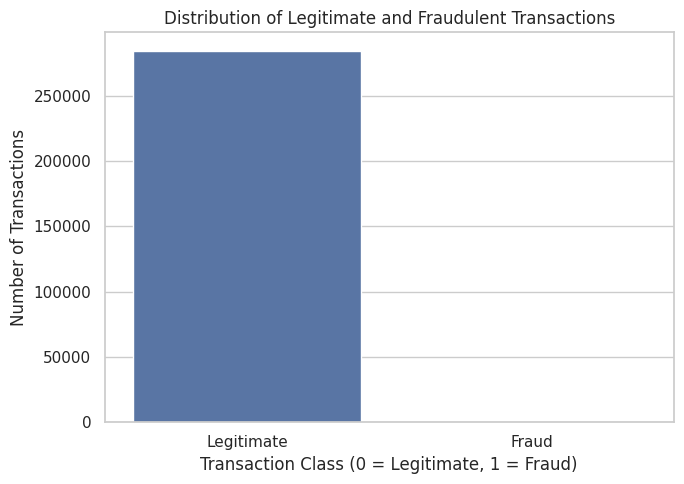

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count each transaction class
class_counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.tight_layout()
plt.show()

In [6]:
# 1. Dataset dimensions
print("Dataset shape:", df.shape)

# 2. Column names
print("\nColumn names:")
print(df.columns.tolist())

# 3. Dataset information
print("\nDataset information:")
df.info()

# 4. Missing values
print("\nTotal missing values:", df.isnull().sum().sum())

# 5. Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 6. Target class distribution
print("\nClass distribution:")
print(df["Class"].value_counts())

# 7. Class percentages
print("\nClass percentages:")
print((df["Class"].value_counts(normalize=True) * 100).round(4))

# 8. Statistical summary
print("\nStatistical summary:")
display(df.describe().T)

Dataset shape: (284807, 31)

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.487313e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.556467e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.213481e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.406331e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


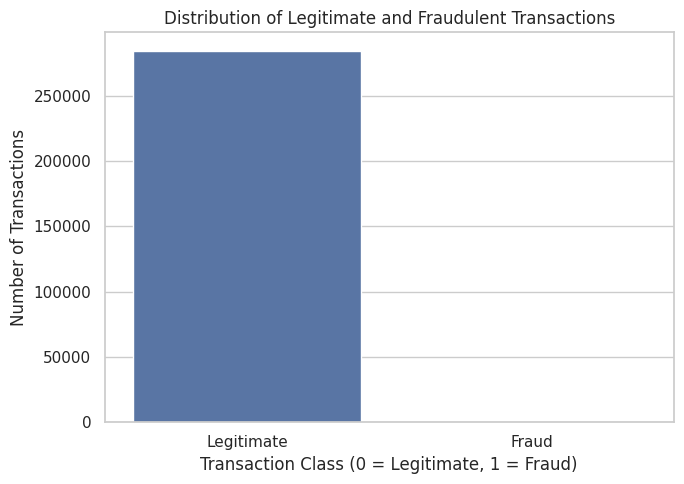

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count each transaction class
class_counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.tight_layout()
plt.show()

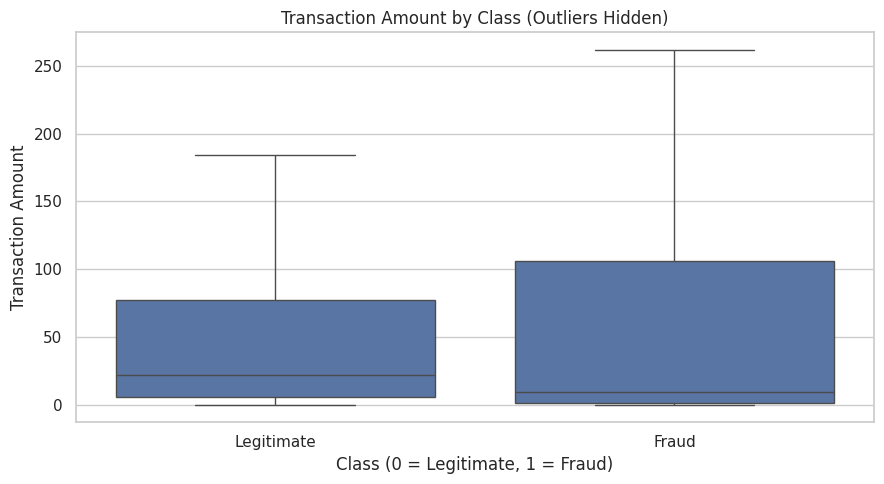

,count,mean,median,std,min,max
Class,,,,,,
0,284315,88.29,22.00,250.11,0.0,25691.16
1,492,122.21,9.25,256.68,0.0,2125.87


In [8]:
# Compare transaction amounts for legitimate and fraudulent transactions

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount",
    showfliers=False
)

plt.title("Transaction Amount by Class (Outliers Hidden)")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount")
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.tight_layout()
plt.show()

# Compare transaction amount statistics
display(
    df.groupby("Class")["Amount"]
      .agg(["count", "mean", "median", "std", "min", "max"])
      .round(2)
)

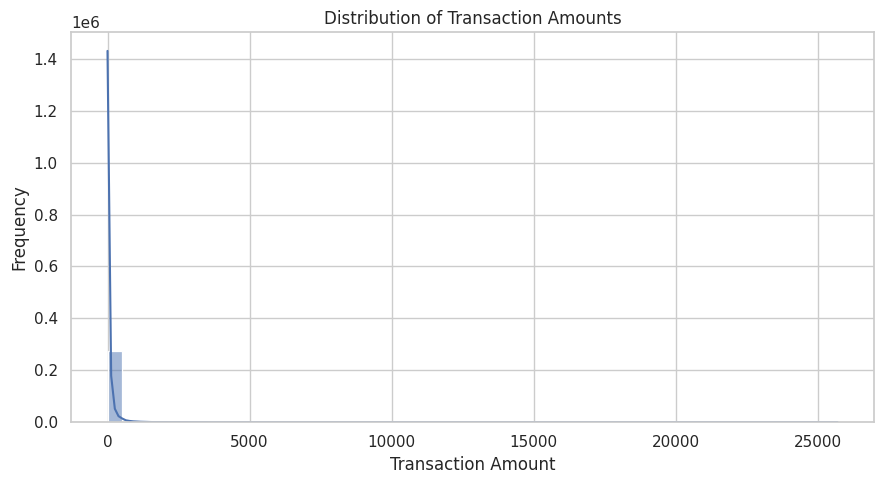

In [9]:
# Visualization 2: Transaction Amount Distribution

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Amount",
    bins=50,
    kde=True
)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

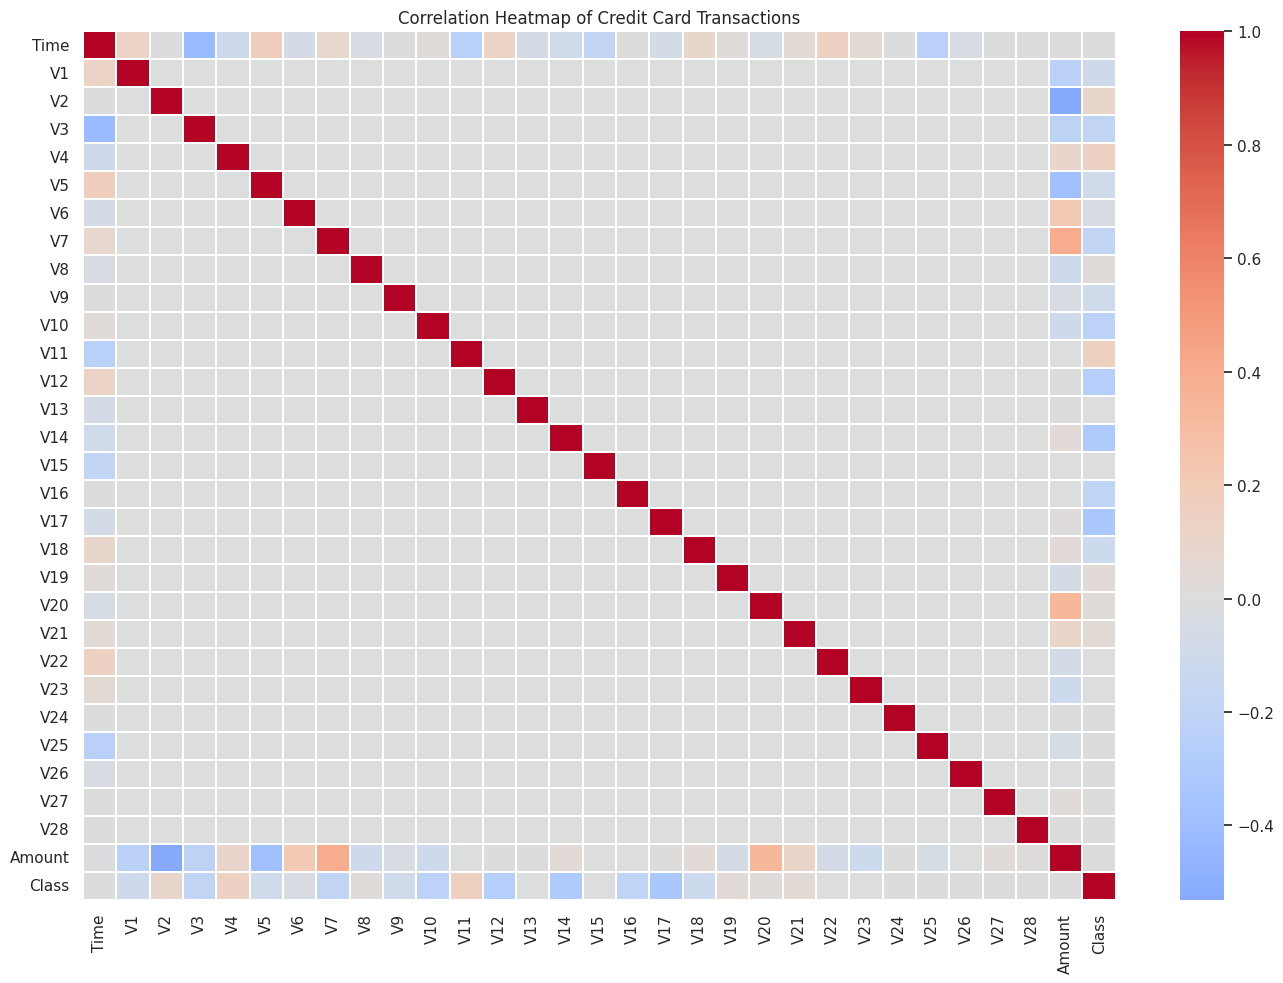

In [10]:
# Visualization 3: Correlation Heatmap

plt.figure(figsize=(14, 10))

correlation_matrix = df.corr(numeric_only=True)

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Correlation Heatmap of Credit Card Transactions")
plt.tight_layout()
plt.show()

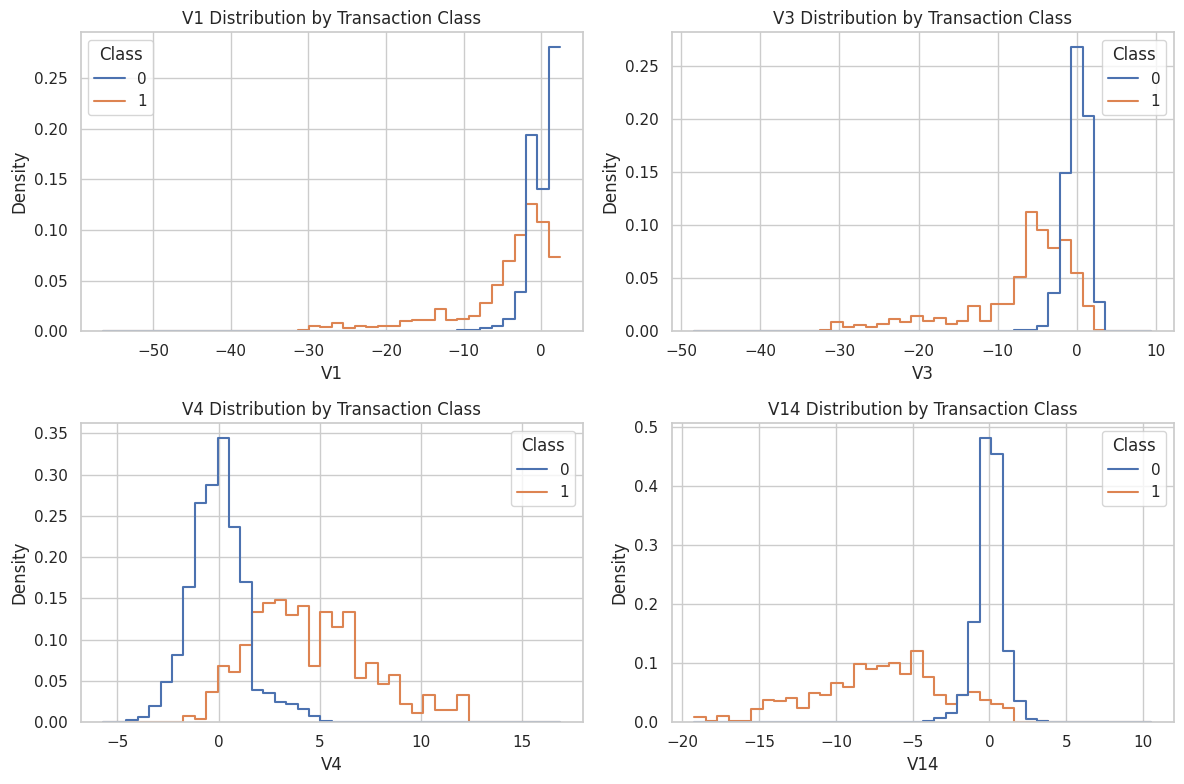

In [11]:
# Visualization 4: Selected Feature Distributions by Class

selected_features = ["V1", "V3", "V4", "V14"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for feature, ax in zip(selected_features, axes.flatten()):
    sns.histplot(
        data=df,
        x=feature,
        hue="Class",
        bins=40,
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        ax=ax
    )

    ax.set_title(f"{feature} Distribution by Transaction Class")
    ax.set_xlabel(feature)
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

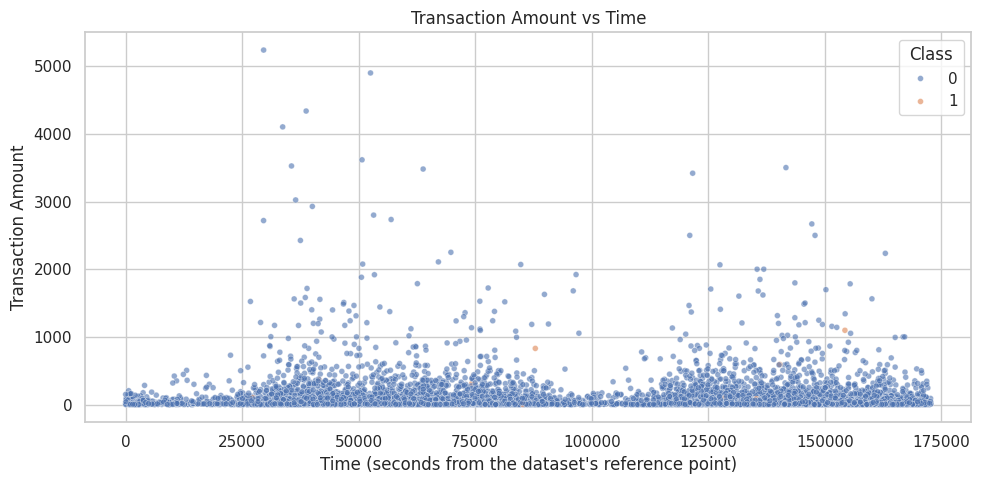

In [12]:
# Visualization 5: Transaction Amount vs Time

# Sample data for a readable plot
plot_df = df.sample(
    n=min(10000, len(df)),
    random_state=42
)

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=plot_df,
    x="Time",
    y="Amount",
    hue="Class",
    alpha=0.6,
    s=18
)

plt.title("Transaction Amount vs Time")
plt.xlabel("Time (seconds from the dataset's reference point)")
plt.ylabel("Transaction Amount")
plt.tight_layout()
plt.show()

In [13]:
# STEP 04.1: Separate features and target

from sklearn.model_selection import train_test_split

X = df.drop(columns=["Class"])
y = df["Class"]

# First, separate the test set (15%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# Split the remaining data into training (70%) and validation (15%)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.1764706,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

Training set: (199364, 30) (199364,)
Validation set: (42721, 30) (42721,)
Test set: (42722, 30) (42722,)


In [14]:
# STEP 04.2: Feature standardization

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit ONLY on training data to prevent data leakage
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same transformation to validation and test sets
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Training data scaled:", X_train_scaled.shape)
print("Validation data scaled:", X_val_scaled.shape)
print("Test data scaled:", X_test_scaled.shape)

Training data scaled: (199364, 30)
Validation data scaled: (42721, 30)
Test data scaled: (42722, 30)


In [15]:
# STEP 04.3: Calculate class weights

from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class weights:", class_weights)

Class weights: {0: 0.5008642347502763, 1: 289.7732558139535}


In [16]:
# STEP 04.4: Verify class distribution in each split

for name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"\n{name} set:")
    print(labels.value_counts().sort_index())
    print(
        "Fraud percentage:",
        round((labels == 1).mean() * 100, 4),
        "%"
    )

print("\nPreprocessing completed successfully!")


Training set:
Class
0    199020
1       344
Name: count, dtype: int64
Fraud percentage: 0.1725 %

Validation set:
Class
0    42647
1       74
Name: count, dtype: int64
Fraud percentage: 0.1732 %

Test set:
Class
0    42648
1       74
Name: count, dtype: int64
Fraud percentage: 0.1732 %

Preprocessing completed successfully!


In [17]:
# STEP 05.1: Build the MLP deep learning model

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Build the neural network
model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),

    Dense(64, activation="relu"),
    Dropout(0.3),

    Dense(32, activation="relu"),
    Dropout(0.2),

    Dense(16, activation="relu"),

    Dense(1, activation="sigmoid")
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="roc_auc"),
        tf.keras.metrics.AUC(
            name="pr_auc",
            curve="PR"
        )
    ]
)

# Display the architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,609 (18.00 KB)

 Trainable params: 4,609 (18.00 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# STEP 05.2: Train the MLP model

early_stopping = EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=30,
    batch_size=2048,
    class_weight=class_weights,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - accuracy: 0.7508 - loss: 0.4404 - pr_auc: 0.4118 - roc_auc: 0.8901 - val_accuracy: 0.9698 - val_loss: 0.3021 - val_pr_auc: 0.7218 - val_roc_auc: 0.9680 - learning_rate: 0.0010
Epoch 2/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9575 - loss: 0.2347 - pr_auc: 0.5904 - roc_auc: 0.9590 - val_accuracy: 0.9718 - val_loss: 0.1505 - val_pr_auc: 0.7368 - val_roc_auc: 0.9685 - learning_rate: 0.0010
Epoch 3/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9634 - loss: 0.2036 - pr_auc: 0.6071 - roc_auc: 0.9658 - val_accuracy: 0.9711 - val_loss: 0.1302 - val_pr_auc: 0.6949 - val_roc_auc: 0.9690 - learning_rate: 0.0010
Epoch 4/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9649 - loss: 0.1657 - pr_auc: 0.6131 - roc_auc: 0.9798 - val_accuracy: 0.9750 - val_loss: 0.1050 - val_pr_auc: 0.6751 - val_roc_auc: 0.9706 - learning_rate: 0.0010
Epoch 5/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9704 - loss: 0.1477

In [19]:
# STEP 05.3: Compare learning rates

from tensorflow.keras.optimizers import Adam

learning_rates = [0.001, 0.0005, 0.0001]
tuning_results = []

for lr in learning_rates:
    print(f"\nTraining with learning rate: {lr}")

    trial_model = tf.keras.models.clone_model(model)

    trial_model.compile(
        optimizer=Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.AUC(
                name="pr_auc",
                curve="PR"
            )
        ]
    )

    trial_history = trial_model.fit(
        X_train_scaled,
        y_train,
        validation_data=(X_val_scaled, y_val),
        epochs=15,
        batch_size=2048,
        class_weight=class_weights,
        callbacks=[
            EarlyStopping(
                monitor="val_pr_auc",
                mode="max",
                patience=3,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    best_val_pr_auc = max(
        trial_history.history["val_pr_auc"]
    )

    tuning_results.append({
        "Learning Rate": lr,
        "Best Validation PR-AUC": best_val_pr_auc,
        "Epochs Trained": len(
            trial_history.history["loss"]
        )
    })

tuning_df = pd.DataFrame(tuning_results)
display(tuning_df.sort_values(
    "Best Validation PR-AUC",
    ascending=False
))


Training with learning rate: 0.001

Training with learning rate: 0.0005

Training with learning rate: 0.0001


,Learning Rate,Best Validation PR-AUC,Epochs Trained
1,0.0005,0.768014,6
2,0.0001,0.761102,13
0,0.0010,0.720489,5


In [20]:
# STEP 06.1: Evaluate the trained model on unseen test data

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Predicted fraud probabilities
y_prob = model.predict(X_test_scaled).ravel()

# Convert probabilities into class predictions
threshold = 0.5
y_pred = (y_prob >= threshold).astype(int)

# Calculate evaluation metrics
print("TEST SET EVALUATION")
print("-" * 40)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

1336/1336 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
TEST SET EVALUATION
----------------------------------------
Accuracy: 0.9707
Precision: 0.0484
Recall: 0.8514
F1-score: 0.0916
ROC-AUC: 0.9579
PR-AUC: 0.6404

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.97      0.99     42648
       Fraud       0.05      0.85      0.09        74

    accuracy                           0.97     42722
   macro avg       0.52      0.91      0.54     42722
weighted avg       1.00      0.97      0.98     42722



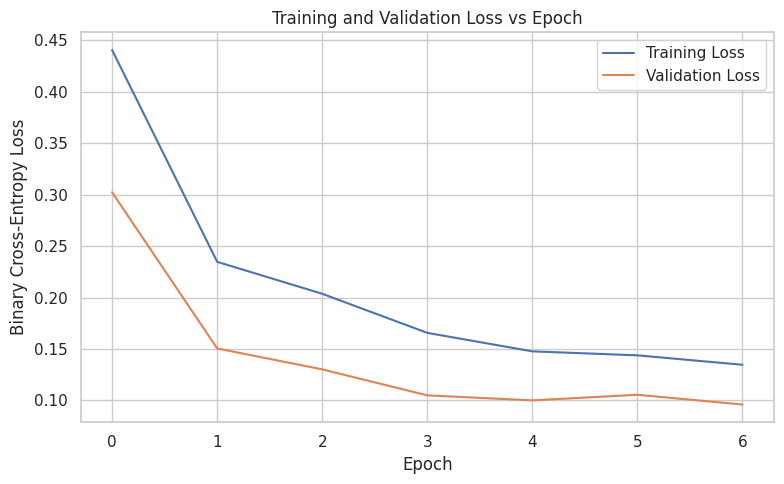

In [21]:
# Visualization 1: Loss vs Epoch

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.tight_layout()
plt.show()

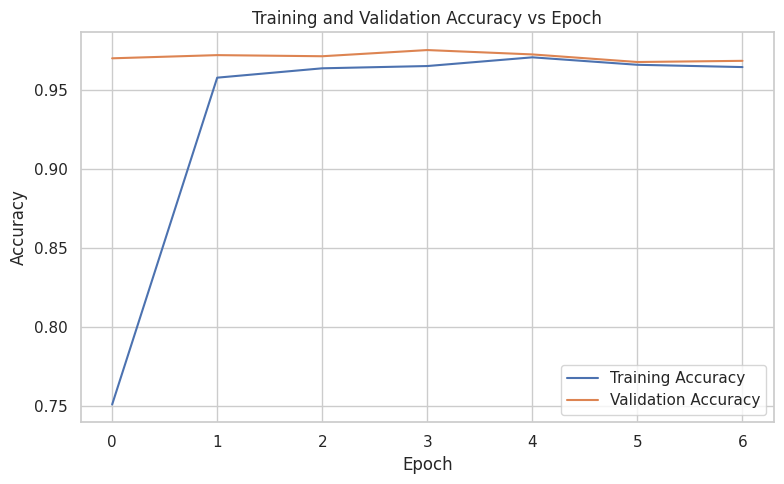

In [22]:
# Visualization 2: Accuracy vs Epoch

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

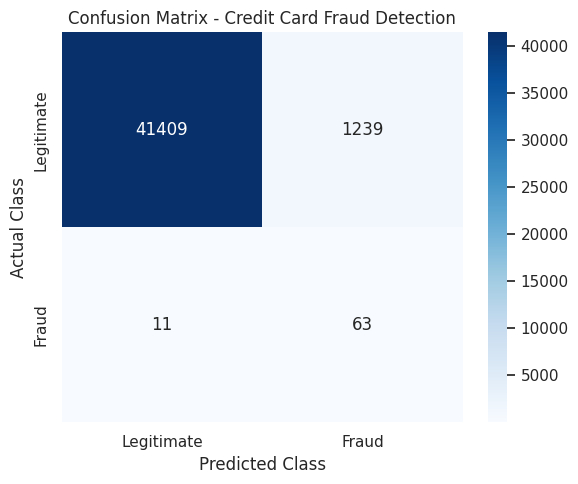

True Negatives: 41409
False Positives: 1239
False Negatives: 11
True Positives: 63


In [23]:
# Visualization 3: Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Confusion Matrix - Credit Card Fraud Detection")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

print("True Negatives:", cm[0, 0])
print("False Positives:", cm[0, 1])
print("False Negatives:", cm[1, 0])
print("True Positives:", cm[1, 1])

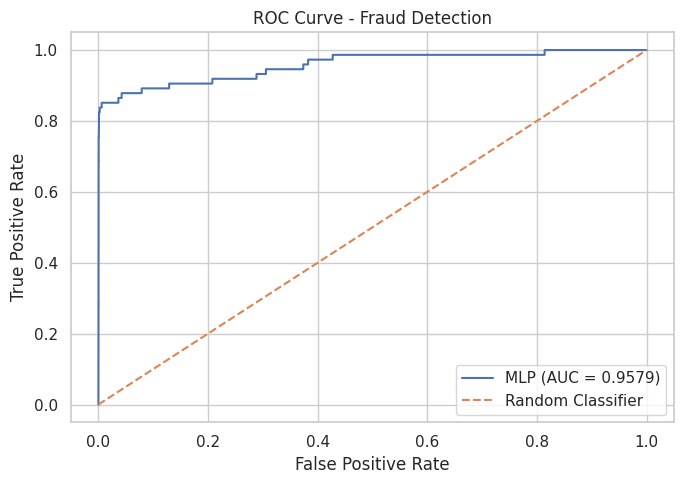

In [24]:
# Visualization 4: ROC Curve

from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f"MLP (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve - Fraud Detection")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

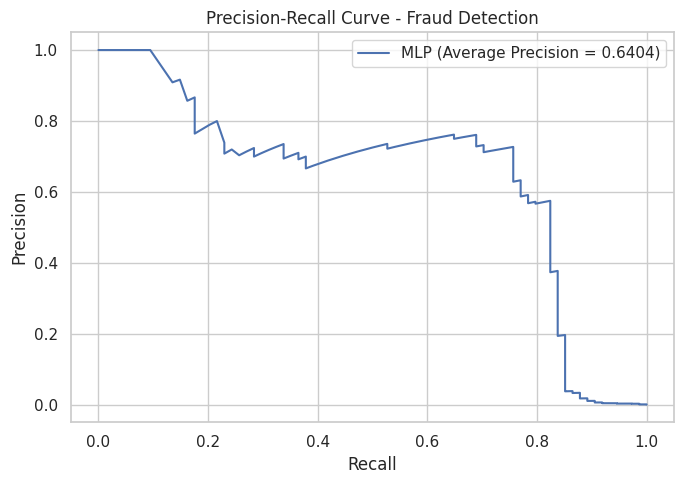

In [25]:
# Additional Visualization: Precision-Recall Curve

from sklearn.metrics import precision_recall_curve

precision_values, recall_values, pr_thresholds = (
    precision_recall_curve(y_test, y_prob)
)

pr_auc = average_precision_score(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    recall_values,
    precision_values,
    label=f"MLP (Average Precision = {pr_auc:.4f})"
)

plt.title("Precision-Recall Curve - Fraud Detection")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
# STEP 07.1: Save actual model evaluation results

import os
import json
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

os.makedirs("fraud_detection_results", exist_ok=True)

# Calculate final test metrics using existing predictions
results = {
    "Test Accuracy": float(accuracy_score(y_test, y_pred)),
    "Test Precision": float(precision_score(y_test, y_pred, zero_division=0)),
    "Test Recall": float(recall_score(y_test, y_pred, zero_division=0)),
    "Test F1 Score": float(f1_score(y_test, y_pred, zero_division=0)),
    "Test ROC-AUC": float(roc_auc_score(y_test, y_prob)),
    "Test Average Precision (PR-AUC)": float(
        average_precision_score(y_test, y_prob)
    ),
    "Classification Threshold": 0.5,
    "Training Samples": int(len(X_train_scaled)),
    "Validation Samples": int(len(X_val_scaled)),
    "Test Samples": int(len(X_test_scaled))
}

with open(
    "fraud_detection_results/evaluation_metrics.json", "w"
) as f:
    json.dump(results, f, indent=4)

# Save training history
pd.DataFrame(history.history).to_csv(
    "fraud_detection_results/training_history.csv",
    index=False
)

# Save test predictions
pd.DataFrame({
    "Actual_Class": np.asarray(y_test),
    "Predicted_Probability": y_prob,
    "Predicted_Class": y_pred
}).to_csv(
    "fraud_detection_results/test_predictions.csv",
    index=False
)

# Save classification report
report = classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Fraud"],
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).T.to_csv(
    "fraud_detection_results/classification_report.csv"
)

# Display actual results
display(pd.DataFrame(
    list(results.items()),
    columns=["Metric", "Value"]
))

print("Results saved successfully!")

,Metric,Value
0,Test Accuracy,0.970741
1,Test Precision,0.048387
2,Test Recall,0.851351
3,Test F1 Score,0.091570
4,Test ROC-AUC,0.957934
5,Test Average Precision (PR-AUC),0.640390
6,Classification Threshold,0.500000
7,Training Samples,199364.000000
8,Validation Samples,42721.000000
9,Test Samples,42722.000000


Results saved successfully!
